<a href="https://colab.research.google.com/github/Kusuma-Ramesh/NeuroScan-AI-Brain-Tumor-Classification/blob/main/NeuroScan_AI_Brain_Tumor_MRI_Classification_Colab_FINAL.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# NeuroScan AI — Brain Tumor MRI Image Classification

**Project type:** Deep learning / multiclass image classification  
**Domain:** Medical imaging  
**Framework:** Python, TensorFlow/Keras, scikit-learn, Streamlit  
**Repository:** [NeuroScan AI — Brain Tumor MRI Classification](https://github.com/Kusuma-Ramesh/NeuroScan-AI-Brain-Tumor-Classification)

## Project summary

This notebook documents an end-to-end image-classification project that predicts one of four dataset labels from a brain MRI image: **glioma, meningioma, no_tumor, or pituitary**. It explores the dataset, checks class balance and image dimensions, applies pixel scaling and training-only augmentation, compares a custom CNN with four ImageNet-pretrained architectures, and reviews evaluation results. The accompanying Streamlit application supports image upload, class-probability display, and Grad-CAM visual explanations.

The current recorded results were obtained from a small dataset and short training runs. Transfer-learning models used five epochs with their pretrained backbones frozen. The custom CNN was run for only two smoke-test epochs and is not a competitive, fully trained baseline. The notebook therefore reports the existing results transparently and does **not** start expensive training automatically.

> **Medical disclaimer:** This is an educational/research prototype, not a medical device. It is not clinically validated and must not be used to diagnose, treat, triage, or make decisions about real patients.

## 1. Environment and project setup

Run this notebook in Google Colab. The code below clones the public project repository and downloads model artifacts tracked with Git LFS. The image dataset is intentionally not stored in GitHub; obtain it from the project dataset source and upload/extract it separately.

In [ ]:
# Colab setup. If the repository already exists in this runtime, reuse it.
from pathlib import Path
import os, sys, subprocess

REPO_URL = "https://github.com/Kusuma-Ramesh/NeuroScan-AI-Brain-Tumor-Classification.git"
REPO_DIR = Path("/content/NeuroScan-AI-Brain-Tumor-Classification")

if not REPO_DIR.exists():
    subprocess.run(["git", "clone", REPO_URL, str(REPO_DIR)], check=True)
subprocess.run(["bash", "-lc", "apt-get update -qq && apt-get install -y git-lfs"], check=False)
subprocess.run(["git", "lfs", "install"], check=False)
subprocess.run(["git", "-C", str(REPO_DIR), "lfs", "pull"], check=False)
os.chdir(REPO_DIR)
sys.path.insert(0, str(REPO_DIR))
print("Repository:", REPO_DIR)
print("README exists:", (REPO_DIR / "README.md").exists())
print("Model files:", [p.name for p in (REPO_DIR / "models").glob("*.h5")])

Repository: /content/NeuroScan-AI-Brain-Tumor-Classification
README exists: True
Model files: ['inceptionv3.h5', 'custom_cnn.h5', 'resnet50.h5', 'mobilenetv2.h5', 'efficientnetb0.h5']


### Dataset location

Download the **Brain Tumor MRI Multi-Class Dataset** from the source linked in the project README. Extract it so the directory structure is `data/Tumour/{train,valid,test}/<class>/`. If using Colab, upload the dataset ZIP and extract it under `/content/NeuroScan-AI-Brain-Tumor-Classification/data/`.

Do not upload the dataset to the public GitHub repository unless you have permission to redistribute it.

In [ ]:
from pathlib import Path
import shutil
import zipfile

REPO_DIR = Path("/content/NeuroScan-AI-Brain-Tumor-Classification")
DATA_DIR = REPO_DIR / "data" / "Tumour"
SPLIT_NAMES = ("train", "valid", "test")

def is_dataset_root(path):
    """True when path has the expected train/valid/test directory layout."""
    path = Path(path)
    return (
        path.is_dir()
        and all((path / split).is_dir() for split in SPLIT_NAMES)
        and any((path / "train" / cls).is_dir()
                for cls in ("glioma", "meningioma", "no_tumor", "pituitary"))
    )

if is_dataset_root(DATA_DIR):
    print("Dataset is already ready:", DATA_DIR)
else:
    # The original dataset ZIP is named Tumour-*.zip; do not use the project ZIP.
    zip_files = sorted(
        p for p in Path("/content").glob("Tumour*.zip")
        if p.is_file()
    )

    if not zip_files:
        print("Dataset ZIP not found.")
        print("Upload the original Tumour-*.zip dataset archive to Colab's /content folder.")
        print("Do not use NeuroScan_AI_Final_Project.zip; it intentionally excludes the dataset.")
    else:
        dataset_zip = zip_files[0]
        staging_dir = Path("/content/_tumour_dataset_extract")
        if staging_dir.exists():
            shutil.rmtree(staging_dir)
        staging_dir.mkdir(parents=True, exist_ok=True)

        print("Dataset ZIP found:", dataset_zip.name)
        print("Extracting dataset archive...")
        with zipfile.ZipFile(dataset_zip, "r") as archive:
            archive.extractall(staging_dir)

        # Archives may contain Tumour/, another wrapper directory, or split folders at the root.
        candidates = [staging_dir] + [p for p in staging_dir.rglob("*") if p.is_dir()]
        dataset_root = next((p for p in candidates if is_dataset_root(p)), None)

        if dataset_root is None:
            print("Extraction finished, but the expected train/valid/test folder layout was not found.")
            print("Expected: Tumour/train/<class>, Tumour/valid/<class>, Tumour/test/<class>")
            print("Top-level extracted items:", [p.name for p in staging_dir.iterdir()][:20])
        else:
            if DATA_DIR.exists():
                shutil.rmtree(DATA_DIR)
            DATA_DIR.parent.mkdir(parents=True, exist_ok=True)
            shutil.copytree(dataset_root, DATA_DIR)
            print("Dataset installed at:", DATA_DIR)
            print("Train folder found:", (DATA_DIR / "train").is_dir())
            print("Validation folder found:", (DATA_DIR / "valid").is_dir())
            print("Test folder found:", (DATA_DIR / "test").is_dir())

        shutil.rmtree(staging_dir, ignore_errors=True)


Dataset ZIP found: Tumour-20260930T115221Z-1-001.zip
Extracting dataset archive...
Dataset installed at: /content/NeuroScan-AI-Brain-Tumor-Classification/data/Tumour
Train folder found: True
Validation folder found: True
Test folder found: True


## 2. Import libraries and define constants

The project uses four class labels and 224 × 224 RGB inputs. The class order must remain consistent between the dataset loader and the saved model.

In [ ]:
import json, math, warnings
from collections import Counter
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from PIL import Image
from IPython.display import display

import tensorflow as tf
from tensorflow import keras
from sklearn.metrics import (
    accuracy_score, precision_score, recall_score, f1_score,
    classification_report, confusion_matrix, ConfusionMatrixDisplay,
    roc_auc_score
)
from scipy.stats import chisquare, chi2_contingency, binomtest

SEED = 42
IMG_SIZE = (224, 224)
BATCH_SIZE = 32
CLASSES = ["glioma", "meningioma", "no_tumor", "pituitary"]
SPLITS = ["train", "valid", "test"]
np.random.seed(SEED)
tf.random.set_seed(SEED)
print("TensorFlow:", tf.__version__)
print("GPU devices:", tf.config.list_physical_devices("GPU"))

TensorFlow: 2.21.0
GPU devices: []


## 3. Dataset audit

The source dataset currently has 2,443 images: 1,695 training, 502 validation, and 246 test images. The next cells verify these counts against the files available in the runtime rather than assuming the uploaded copy is identical.

In [ ]:
def count_images(data_dir):
    extensions = {".jpg", ".jpeg", ".png", ".bmp", ".webp"}
    rows = []
    for split in SPLITS:
        for cls in CLASSES:
            folder = Path(data_dir) / split / cls
            files = [p for p in folder.iterdir() if p.is_file() and p.suffix.lower() in extensions] if folder.exists() else []
            rows.append({"split": split, "class": cls, "count": len(files), "folder_exists": folder.exists()})
    return pd.DataFrame(rows)

if DATA_DIR.exists():
    counts_df = count_images(DATA_DIR)
    display(counts_df.pivot(index="class", columns="split", values="count").reindex(CLASSES))
    print("Total images:", int(counts_df["count"].sum()))
else:
    counts_df = pd.DataFrame(columns=["split", "class", "count", "folder_exists"])
    print("Set up DATA_DIR first, then rerun this cell.")

split,test,train,valid
class,,,
glioma,80,564,161
meningioma,63,358,124
no_tumor,49,335,99
pituitary,54,438,118


Total images: 2443


In [ ]:
if not counts_df.empty:
    split_totals = counts_df.groupby("split")["count"].sum().reindex(SPLITS)
    display(split_totals.rename("images").to_frame())
    expected = {"train": 1695, "valid": 502, "test": 246}
    print("Expected project counts:", expected)
    print("Observed counts:", split_totals.to_dict())
    print("Counts match reference:", all(int(split_totals[s]) == expected[s] for s in SPLITS))

,images
split,
train,1695
valid,502
test,246


Expected project counts: {'train': 1695, 'valid': 502, 'test': 246}
Observed counts: {'train': 1695, 'valid': 502, 'test': 246}
Counts match reference: True


In [ ]:
# Count missing class directories and unsupported/empty class folders.
if DATA_DIR.exists():
    folder_audit = []
    for split in SPLITS:
        for cls in CLASSES:
            folder = DATA_DIR / split / cls
            files = list(folder.glob("*")) if folder.exists() else []
            folder_audit.append({
                "split": split, "class": cls, "directory_exists": folder.exists(),
                "file_count": sum(p.is_file() for p in files)
            })
    display(pd.DataFrame(folder_audit))

,split,class,directory_exists,file_count
0,train,glioma,True,564
1,train,meningioma,True,358
2,train,no_tumor,True,335
3,train,pituitary,True,438
4,valid,glioma,True,161
5,valid,meningioma,True,124
6,valid,no_tumor,True,99
7,valid,pituitary,True,118
8,test,glioma,True,80
9,test,meningioma,True,63


### Dataset observations

The training set is imbalanced: glioma has the largest training count (564), while no_tumor has the smallest (335). The project addresses this using class weights during training rather than deleting examples. Images are resized consistently to 224 × 224 pixels; this is a model input transformation, not a claim that source files all have identical dimensions.

## 4. Visual exploration

### Chart 1 — Number of images by class and split

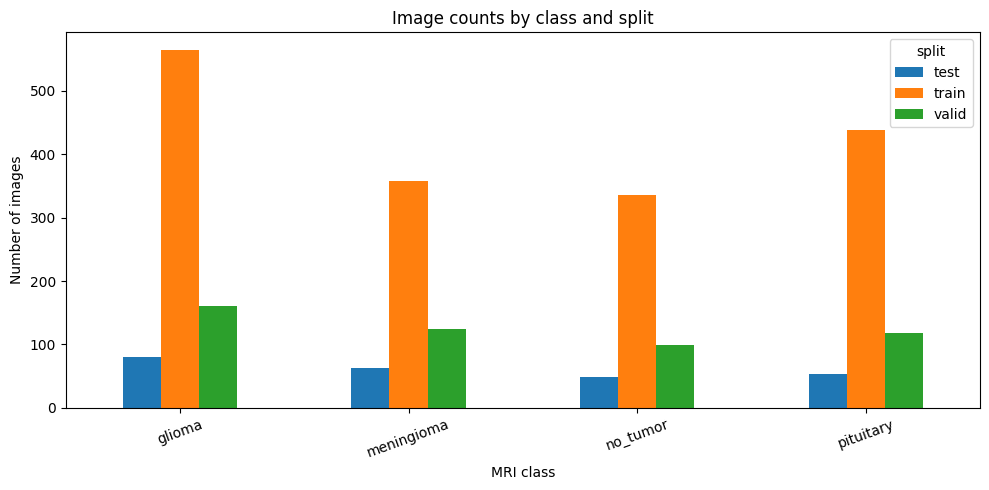

In [ ]:
if not counts_df.empty:
    pivot_counts = counts_df.pivot(index="class", columns="split", values="count").reindex(CLASSES)
    ax = pivot_counts.plot(kind="bar", figsize=(10, 5))
    ax.set_title("Image counts by class and split")
    ax.set_xlabel("MRI class"); ax.set_ylabel("Number of images")
    plt.xticks(rotation=20); plt.tight_layout(); plt.show()

**Why this chart?** A grouped bar chart compares class representation across train, validation, and test partitions.  
**Insight:** The reference training counts are 564 glioma, 358 meningioma, 335 no_tumor, and 438 pituitary.  
**Business relevance:** Class imbalance can bias a classifier toward more frequent labels. The chart supports decisions about class weights and per-class evaluation.

### Chart 2 — Overall class distribution

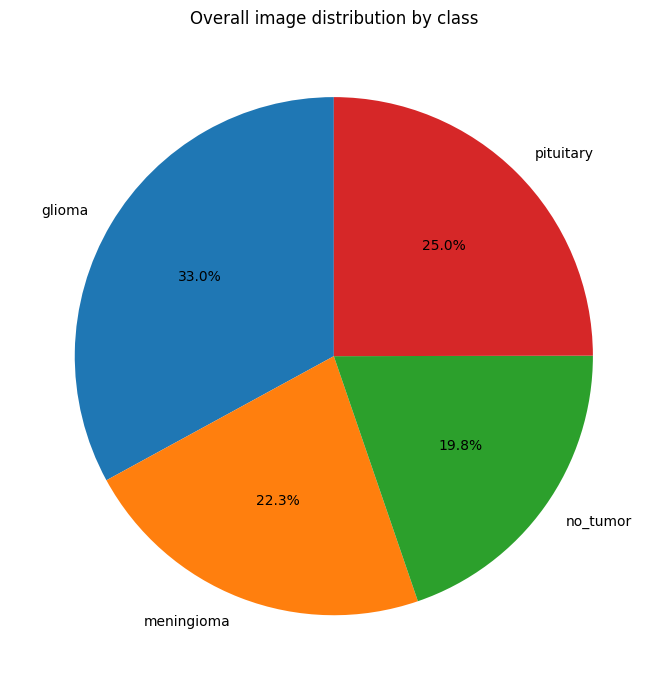

In [ ]:
if not counts_df.empty:
    totals = counts_df.groupby("class")["count"].sum().reindex(CLASSES)
    plt.figure(figsize=(7, 7))
    plt.pie(totals, labels=totals.index, autopct="%1.1f%%", startangle=90)
    plt.title("Overall image distribution by class")
    plt.tight_layout(); plt.show()

**Why this chart?** A pie chart gives a quick view of the overall share contributed by each class.  
**Insight:** No class should be interpreted as equally represented merely because the task has four labels.  
**Business relevance:** The model should be judged using macro-averaged precision, recall, and F1—not accuracy alone.

### Chart 3 — Split sizes

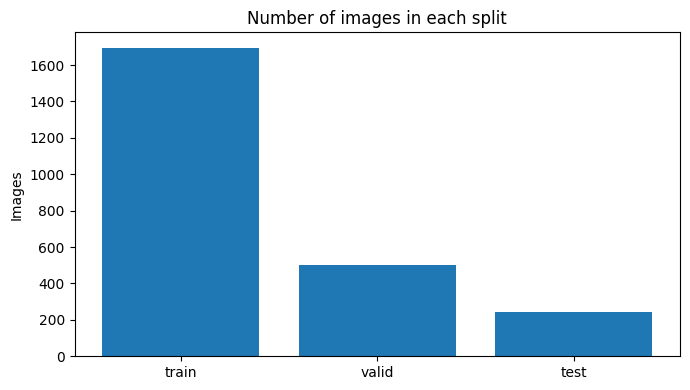

In [ ]:
if not counts_df.empty:
    totals = counts_df.groupby("split")["count"].sum().reindex(SPLITS)
    plt.figure(figsize=(7, 4))
    plt.bar(totals.index, totals.values)
    plt.title("Number of images in each split")
    plt.ylabel("Images"); plt.tight_layout(); plt.show()

**Why this chart?** It checks that each partition contains enough examples for its intended role.  
**Insight:** The reference split is 1,695 train, 502 validation, and 246 test images.  
**Business relevance:** A held-out test set gives a more realistic estimate than training accuracy, although a small test set still creates uncertainty.

### Chart 4 — Sample MRI images

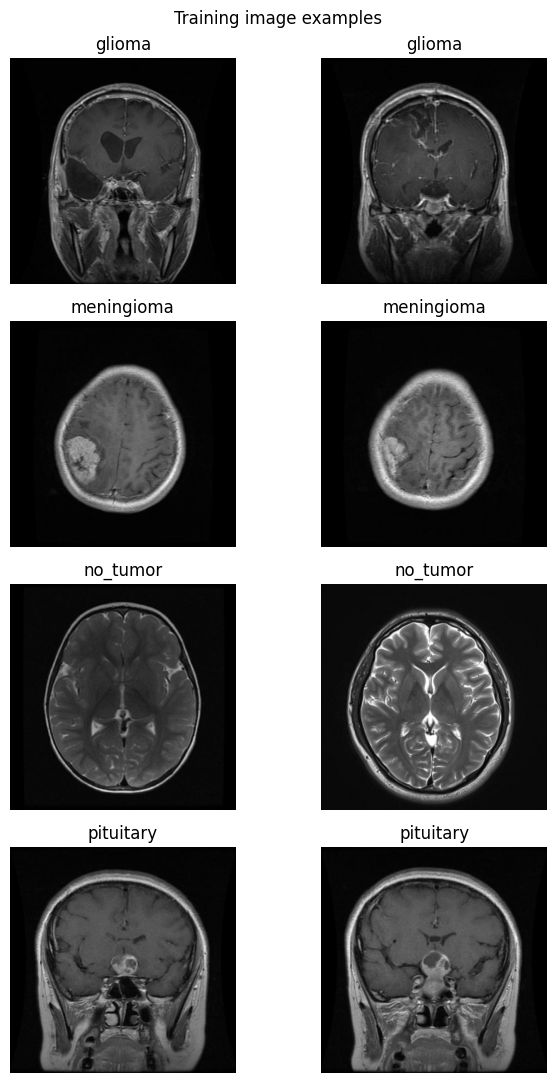

In [ ]:
def list_images(split, max_per_class=2):
    exts = {".jpg", ".jpeg", ".png", ".bmp", ".webp"}
    result = {}
    for cls in CLASSES:
        folder = DATA_DIR / split / cls
        result[cls] = sorted([p for p in folder.iterdir() if p.suffix.lower() in exts])[:max_per_class] if folder.exists() else []
    return result

if DATA_DIR.exists():
    samples = list_images("train", 2)
    fig, axes = plt.subplots(len(CLASSES), 2, figsize=(7, 11))
    for r, cls in enumerate(CLASSES):
        for c in range(2):
            axes[r, c].axis("off")
            if c < len(samples[cls]):
                with Image.open(samples[cls][c]) as im:
                    axes[r, c].imshow(im.convert("RGB"))
                axes[r, c].set_title(cls)
    plt.suptitle("Training image examples"); plt.tight_layout(); plt.show()

**Why this chart?** A sample grid checks label-folder consistency and provides a qualitative view of the MRI images.  
**Insight:** Visual review can reveal inconsistent image formats, unexpected content, or obvious labeling problems, but cannot establish diagnostic validity.  
**Business relevance:** Dataset quality review is essential before model development; any suspicious labels should be investigated by qualified reviewers.

### Chart 5 — Source image dimensions

,,sampled_count
width,height,
640,640,400


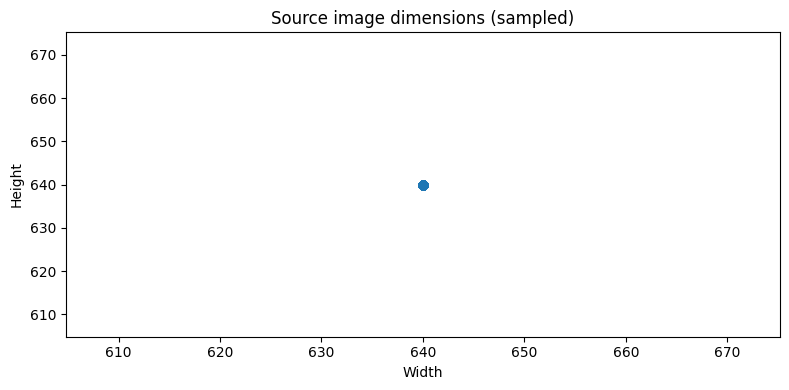

In [ ]:
if DATA_DIR.exists():
    dim_rows = []
    for cls in CLASSES:
        paths = list_images("train", 100)[cls]
        for path in paths:
            try:
                with Image.open(path) as im:
                    dim_rows.append({"class": cls, "width": im.width, "height": im.height})
            except Exception as exc:
                print("Could not read", path.name, exc)
    dims_df = pd.DataFrame(dim_rows)
    if not dims_df.empty:
        display(dims_df.groupby(["width", "height"]).size().sort_values(ascending=False).head(10).rename("sampled_count").to_frame())
        plt.figure(figsize=(8, 4))
        plt.scatter(dims_df["width"], dims_df["height"], alpha=.5)
        plt.title("Source image dimensions (sampled)"); plt.xlabel("Width"); plt.ylabel("Height")
        plt.tight_layout(); plt.show()

**Why this chart?** It identifies variation in source dimensions before resizing.  
**Insight:** The project resizes images to 224 × 224 at load time, regardless of their original dimensions. The sample shown is not a full-dataset resolution census.  
**Business relevance:** Consistent tensor dimensions are required for batching and model inference.

### Chart 6 — Example augmentation

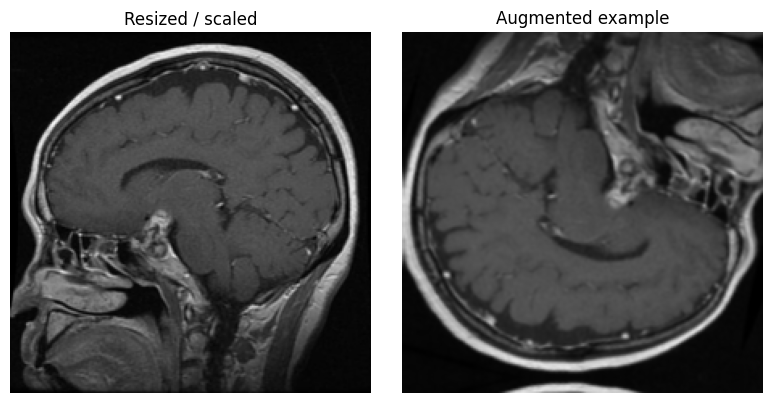

In [ ]:
augmentation = keras.Sequential([
    keras.layers.RandomFlip("horizontal_and_vertical", seed=SEED),
    keras.layers.RandomRotation(0.1, seed=SEED),
    keras.layers.RandomZoom(0.15, seed=SEED),
    keras.layers.RandomTranslation(0.1, 0.1, seed=SEED),
], name="augmentation_preview")

if DATA_DIR.exists():
    sample_path = next((p for p in (DATA_DIR / "train").rglob("*") if p.is_file() and p.suffix.lower() in {".jpg",".jpeg",".png",".bmp",".webp"}), None)
    if sample_path:
        with Image.open(sample_path) as im:
            image_array = np.asarray(im.convert("RGB").resize(IMG_SIZE), dtype=np.float32) / 255.0
        batch = np.expand_dims(image_array, 0)
        aug = augmentation(batch, training=True).numpy()[0]
        fig, ax = plt.subplots(1, 2, figsize=(8, 4))
        ax[0].imshow(image_array); ax[0].set_title("Resized / scaled"); ax[0].axis("off")
        ax[1].imshow(np.clip(aug, 0, 1)); ax[1].set_title("Augmented example"); ax[1].axis("off")
        plt.tight_layout(); plt.show()

**Why this chart?** Side-by-side examples help confirm that augmentation changes training images without changing their labels.  
**Insight:** The pipeline uses flips, rotation, zoom, translation, and brightness augmentation during training only.  
**Business relevance:** Moderate augmentation can reduce overfitting, but transformations must preserve medically meaningful orientation and anatomy. Clinical suitability requires expert review.

### Chart 7 — Model accuracy comparison

,model,accuracy,precision_macro,recall_macro,f1_macro,auc_macro,params,size_mb,latency_ms,score
0,mobilenetv2,0.841463,0.848941,0.848998,0.843269,0.971405,2592068,13.578080,29.392641,0.890289
3,resnet50,0.833333,0.843607,0.841723,0.835785,0.974125,24121476,101.330912,173.949041,0.585049
2,inceptionv3,0.804878,0.804938,0.806430,0.796593,0.960629,22336548,94.590904,83.748317,0.662733
1,efficientnetb0,0.796748,0.802375,0.801212,0.790220,0.959911,4383655,20.938672,87.164720,0.780624
4,custom_cnn,0.325203,0.081301,0.250000,0.122699,0.751899,1240516,15.004200,40.786627,0.371629


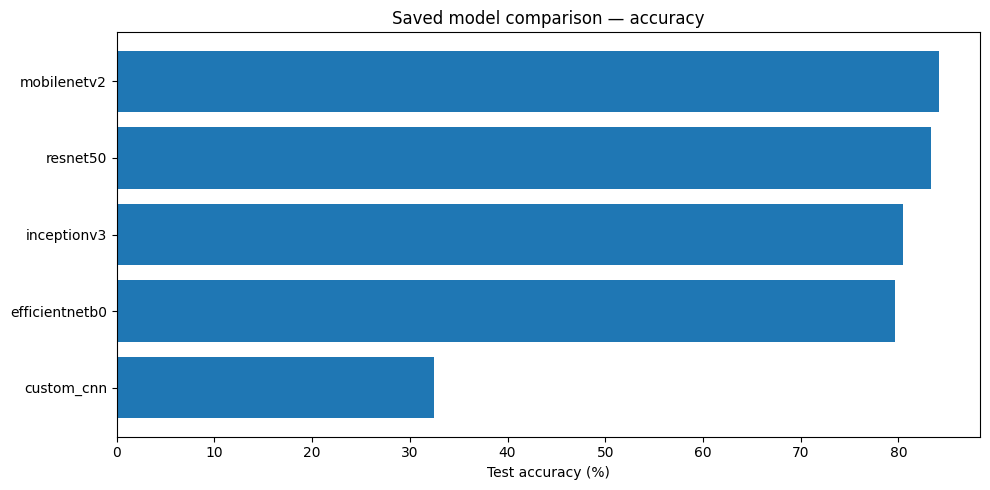

In [ ]:
comparison_path = REPO_DIR / "reports" / "comparison.csv"
if comparison_path.exists():
    comparison = pd.read_csv(comparison_path)
    comparison["model"] = comparison["model"].astype(str)
    display(comparison.sort_values("accuracy", ascending=False))
    plt.figure(figsize=(10, 5))
    ordered = comparison.sort_values("accuracy", ascending=True)
    plt.barh(ordered["model"], ordered["accuracy"] * 100)
    plt.xlabel("Test accuracy (%)"); plt.title("Saved model comparison — accuracy")
    plt.tight_layout(); plt.show()
else:
    comparison = pd.DataFrame()
    print("comparison.csv not found. Confirm the repository clone completed.")

**Why this chart?** Accuracy provides an intuitive first comparison of correct predictions on the held-out test split.  
**Insight from the recorded run:** MobileNetV2 achieved 84.15%, ResNet50 83.33%, InceptionV3 80.49%, EfficientNetB0 79.67%, and the two-epoch custom CNN baseline 32.52%.  
**Business relevance:** Higher accuracy is useful, but is not sufficient for medical use; errors by class, sensitivity, dataset bias, and external validation matter.

### Chart 8 — Macro precision, recall, and F1

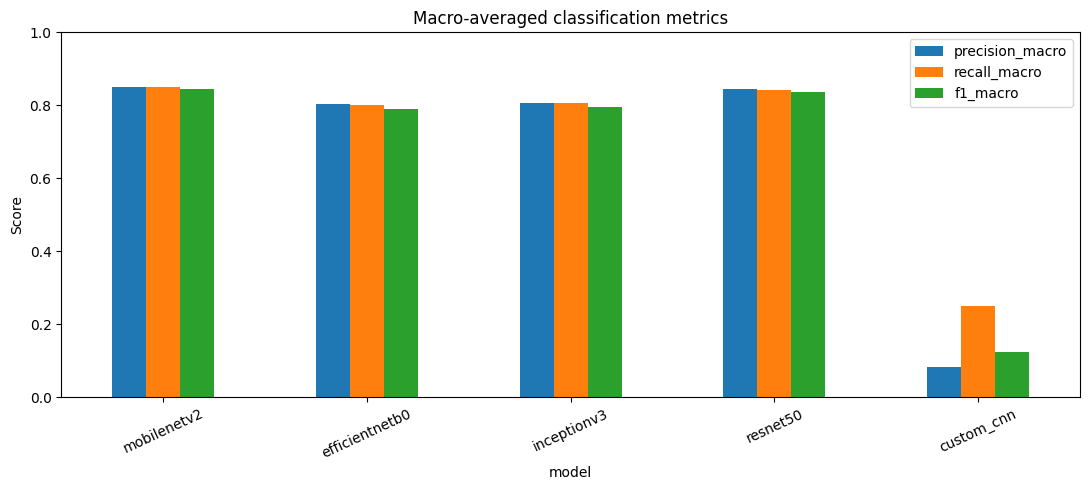

In [ ]:
if not comparison.empty:
    metric_cols = ["precision_macro", "recall_macro", "f1_macro"]
    available = [c for c in metric_cols if c in comparison.columns]
    if available:
        comparison.set_index("model")[available].plot(kind="bar", figsize=(11, 5))
        plt.title("Macro-averaged classification metrics")
        plt.ylabel("Score"); plt.ylim(0, 1); plt.xticks(rotation=25)
        plt.tight_layout(); plt.show()

**Why this chart?** Macro metrics give each class equal weight, reducing the chance that a larger class hides poor performance on a smaller one.  
**Insight:** MobileNetV2 has the strongest recorded macro F1 (84.33%) among these runs.  
**Business relevance:** Per-class balance matters when missing a category could have different consequences. These metrics still do not establish clinical safety.

### Chart 9 — ROC-AUC comparison

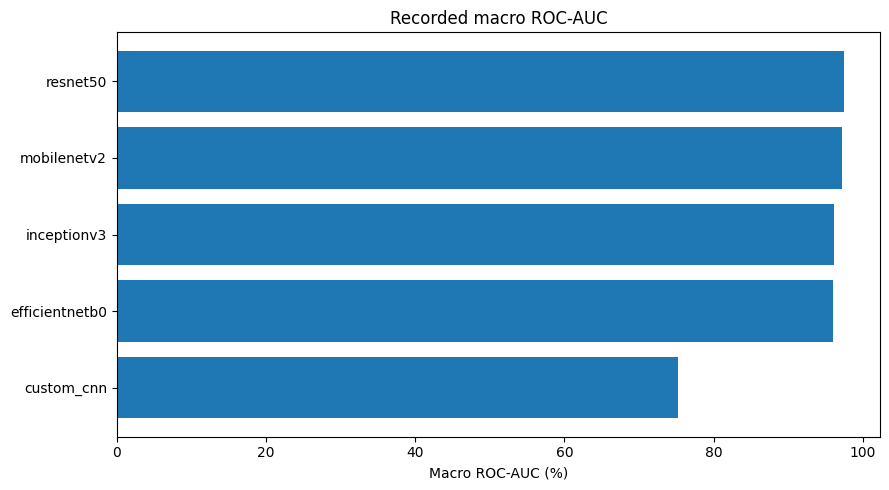

In [ ]:
if not comparison.empty and "auc_macro" in comparison.columns:
    ordered = comparison.sort_values("auc_macro")
    plt.figure(figsize=(9, 5))
    plt.barh(ordered["model"], ordered["auc_macro"] * 100)
    plt.xlabel("Macro ROC-AUC (%)"); plt.title("Recorded macro ROC-AUC")
    plt.tight_layout(); plt.show()

**Why this chart?** ROC-AUC measures how well model scores rank positive versus negative examples across thresholds in a one-vs-rest multiclass calculation.  
**Insight:** ResNet50's recorded macro ROC-AUC is 97.41%, slightly higher than MobileNetV2's 97.14%, despite lower accuracy.  
**Business relevance:** AUC adds information beyond one decision threshold, but does not replace sensitivity/specificity analysis or clinical validation.

### Chart 10 — Model size and inference latency

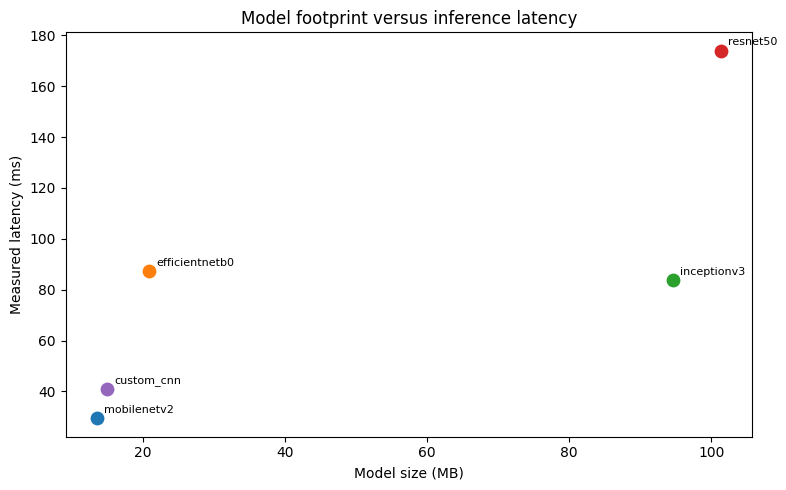

In [ ]:
if not comparison.empty and {"size_mb", "latency_ms"}.issubset(comparison.columns):
    plt.figure(figsize=(8, 5))
    for _, row in comparison.iterrows():
        plt.scatter(row["size_mb"], row["latency_ms"], s=80)
        plt.annotate(row["model"], (row["size_mb"], row["latency_ms"]), xytext=(5, 4), textcoords="offset points", fontsize=8)
    plt.xlabel("Model size (MB)"); plt.ylabel("Measured latency (ms)")
    plt.title("Model footprint versus inference latency")
    plt.tight_layout(); plt.show()

**Why this chart?** A scatter plot shows the trade-off between artifact size and measured inference latency.  
**Insight:** MobileNetV2 is relatively small (13.58 MB) and fast in the recorded environment (29.39 ms). ResNet50 is much larger (101.33 MB) and slower (173.95 ms).  
**Business relevance:** A smaller model can be easier to deploy, but latency depends on hardware and measurement conditions and is not a universal benchmark.

### Chart 11 — Training and validation accuracy

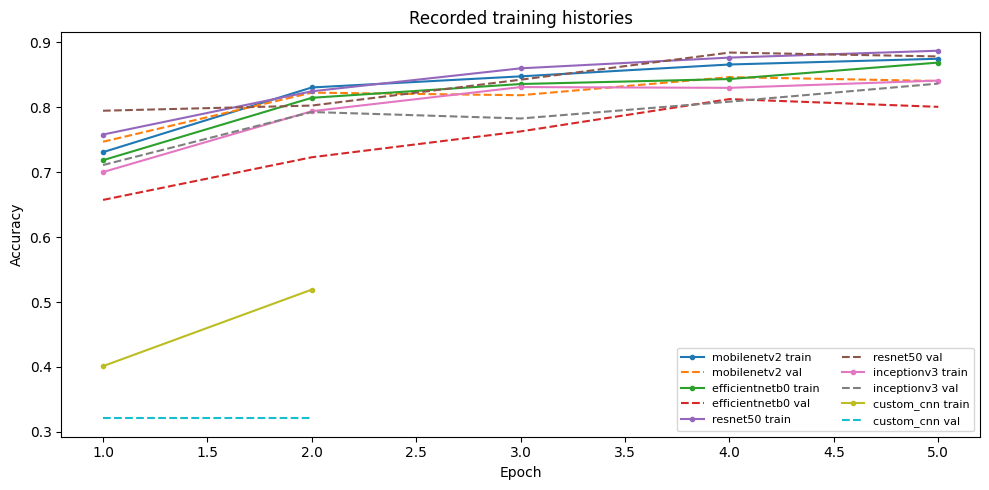

In [ ]:
history_dir = REPO_DIR / "reports"
history_names = ["mobilenetv2", "efficientnetb0", "resnet50", "inceptionv3", "custom_cnn"]
fig, ax = plt.subplots(figsize=(10, 5))
plotted = False
for name in history_names:
    fp = history_dir / f"{name}_history.json"
    if fp.exists():
        h = json.loads(fp.read_text(encoding="utf-8"))
        if "accuracy" in h:
            ax.plot(range(1, len(h["accuracy"])+1), h["accuracy"], marker=".", label=f"{name} train")
            plotted = True
        if "val_accuracy" in h:
            ax.plot(range(1, len(h["val_accuracy"])+1), h["val_accuracy"], linestyle="--", label=f"{name} val")
            plotted = True
if plotted:
    ax.set_xlabel("Epoch"); ax.set_ylabel("Accuracy"); ax.set_title("Recorded training histories")
    ax.legend(ncol=2, fontsize=8); plt.tight_layout(); plt.show()
else:
    print("No training history JSON files were found.")

**Why this chart?** Training and validation curves help identify underfitting, overfitting, and whether further training may help.  
**Insight:** The custom CNN history represents only a two-epoch smoke test. Transfer-learning histories represent five frozen-backbone epochs.  
**Business relevance:** Training curves guide model-development decisions, but final model selection should use held-out evaluation and avoid repeated test-set tuning.

### Chart 12 — Training and validation loss

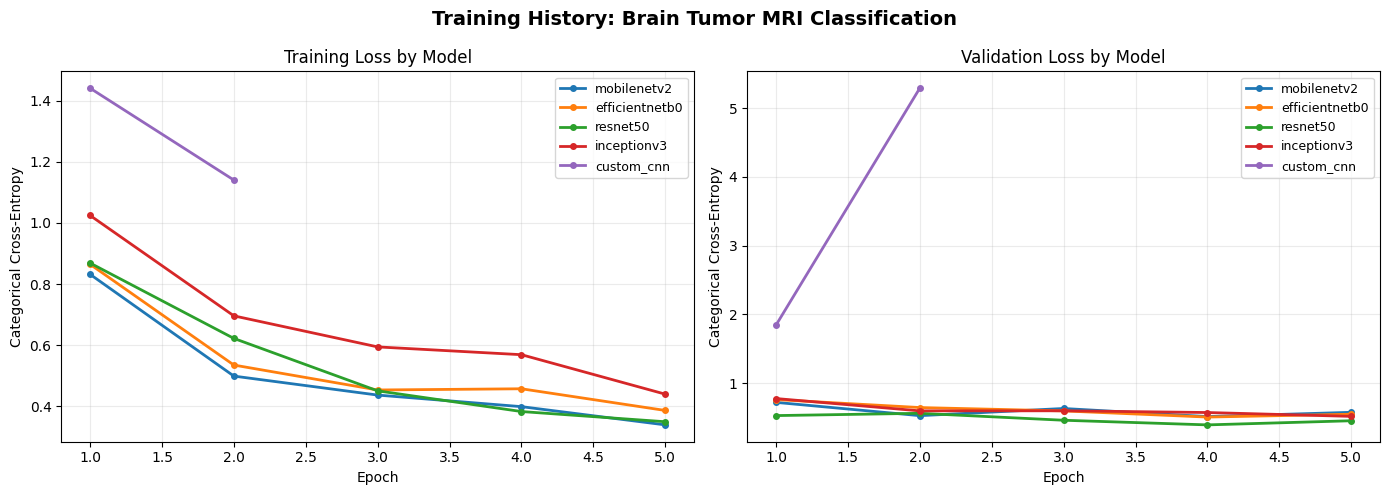

In [ ]:

import json
import matplotlib.pyplot as plt

fig, axes = plt.subplots(1, 2, figsize=(14, 5))

colors = plt.cm.tab10.colors
plotted_train = False
plotted_val = False

for i, name in enumerate(history_names):
    fp = history_dir / f"{name}_history.json"

    if not fp.exists():
        continue

    h = json.loads(fp.read_text(encoding="utf-8"))
    color = colors[i % len(colors)]

    if "loss" in h and h["loss"]:
        epochs = range(1, len(h["loss"]) + 1)
        axes[0].plot(
            epochs, h["loss"],
            marker="o", markersize=4, linewidth=2,
            color=color, label=name
        )
        plotted_train = True

    if "val_loss" in h and h["val_loss"]:
        epochs = range(1, len(h["val_loss"]) + 1)
        axes[1].plot(
            epochs, h["val_loss"],
            marker="o", markersize=4, linewidth=2,
            color=color, label=name
        )
        plotted_val = True

if plotted_train or plotted_val:
    axes[0].set_title("Training Loss by Model")
    axes[0].set_xlabel("Epoch")
    axes[0].set_ylabel("Categorical Cross-Entropy")
    axes[0].grid(True, alpha=0.25)

    axes[1].set_title("Validation Loss by Model")
    axes[1].set_xlabel("Epoch")
    axes[1].set_ylabel("Categorical Cross-Entropy")
    axes[1].grid(True, alpha=0.25)

    if plotted_train:
        axes[0].legend(fontsize=9, frameon=True)
    if plotted_val:
        axes[1].legend(fontsize=9, frameon=True)

    fig.suptitle("Training History: Brain Tumor MRI Classification",
                 fontsize=14, fontweight="bold")
    plt.tight_layout()
    plt.show()
else:
    print("No training history JSON files were found.")


**Why this chart?** Loss often reveals unstable learning or overfitting earlier than accuracy.  
**Insight:** Validation loss should be interpreted alongside validation accuracy; a single epoch's result is not sufficient.  
**Business relevance:** Early stopping and learning-rate reduction can limit wasted training time and improve generalization.

### Chart 13 — Confusion matrix from an optional evaluation run

In [ ]:
# Optional: evaluate one saved model on the held-out test set. This runs inference only, not training.
# It requires the dataset to be present and the saved H5 model to have downloaded successfully.
RUN_TEST_INFERENCE = False

if RUN_TEST_INFERENCE and DATA_DIR.exists():
    test_ds = tf.keras.utils.image_dataset_from_directory(
        DATA_DIR / "test", image_size=IMG_SIZE, batch_size=BATCH_SIZE,
        label_mode="int", class_names=CLASSES, shuffle=False
    )
    test_ds_scaled = test_ds.map(lambda x, y: (tf.cast(x, tf.float32) / 255.0, y))
    model_path = REPO_DIR / "models" / "mobilenetv2.h5"
    model = keras.models.load_model(model_path, compile=False)
    y_true = np.concatenate([y.numpy() for _, y in test_ds_scaled])
    y_prob = model.predict(test_ds_scaled, verbose=1)
    y_pred = np.argmax(y_prob, axis=1)
    ConfusionMatrixDisplay.from_predictions(y_true, y_pred, display_labels=CLASSES, xticks_rotation=25)
    plt.title("MobileNetV2 confusion matrix")
    plt.tight_layout(); plt.show()
    print(classification_report(y_true, y_pred, target_names=CLASSES, zero_division=0))
else:
    print("Inference is disabled by default. Set RUN_TEST_INFERENCE=True after verifying dataset/model paths.")

Inference is disabled by default. Set RUN_TEST_INFERENCE=True after verifying dataset/model paths.


**Why this chart?** A confusion matrix reveals which class pairs are confused, which aggregate accuracy cannot show.  
**Insight:** No new confusion-matrix counts are asserted unless the optional inference cell is run successfully.  
**Business relevance:** Class-specific false negatives and false positives would need expert review before any clinical application.

### Chart 14 — Dataset split by class heatmap

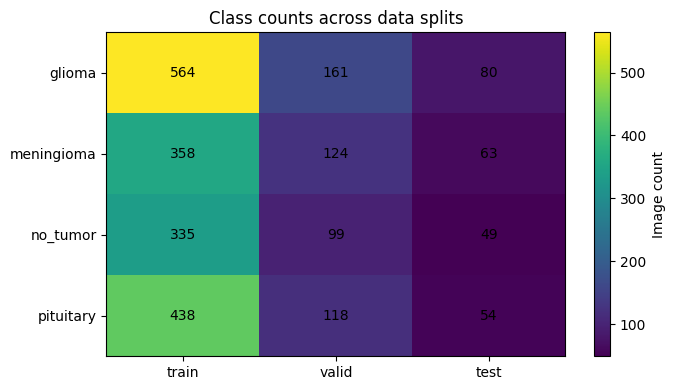

In [ ]:
if not counts_df.empty:
    matrix = counts_df.pivot(index="class", columns="split", values="count").reindex(CLASSES)[SPLITS]
    plt.figure(figsize=(7, 4))
    plt.imshow(matrix.values, aspect="auto")
    plt.colorbar(label="Image count")
    plt.xticks(range(len(SPLITS)), SPLITS); plt.yticks(range(len(CLASSES)), CLASSES)
    for i in range(matrix.shape[0]):
        for j in range(matrix.shape[1]):
            plt.text(j, i, int(matrix.iloc[i, j]), ha="center", va="center")
    plt.title("Class counts across data splits")
    plt.tight_layout(); plt.show()

**Why this chart?** A heatmap makes uneven class counts across partitions easy to identify.  
**Insight:** It should be checked that all four classes are represented in all three splits and that no split is accidentally missing a class.  
**Business relevance:** Inconsistent splits can distort evaluation and hide weaknesses.

### Chart 15 — Model comparison table

In [ ]:
if not comparison.empty:
    cols = [c for c in ["model", "accuracy", "precision_macro", "recall_macro", "f1_macro", "auc_macro", "size_mb", "latency_ms"] if c in comparison.columns]
    display(comparison[cols].sort_values("f1_macro", ascending=False).style.format({
        "accuracy":"{:.2%}", "precision_macro":"{:.2%}", "recall_macro":"{:.2%}",
        "f1_macro":"{:.2%}", "auc_macro":"{:.2%}", "size_mb":"{:.2f}", "latency_ms":"{:.2f}"
    }))

,model,accuracy,precision_macro,recall_macro,f1_macro,auc_macro,size_mb,latency_ms
0,mobilenetv2,84.15%,84.89%,84.90%,84.33%,97.14%,13.58,29.39
3,resnet50,83.33%,84.36%,84.17%,83.58%,97.41%,101.33,173.95
2,inceptionv3,80.49%,80.49%,80.64%,79.66%,96.06%,94.59,83.75
1,efficientnetb0,79.67%,80.24%,80.12%,79.02%,95.99%,20.94,87.16
4,custom_cnn,32.52%,8.13%,25.00%,12.27%,75.19%,15.00,40.79


**Why this table?** A multi-metric comparison prevents choosing a model based on accuracy alone.  
**Insight:** MobileNetV2 is the most balanced practical candidate in the recorded runs; ResNet50 has slightly higher macro AUC but a much larger footprint and slower latency.  
**Business relevance:** Model choice should balance predictive performance, error costs, speed, size, fairness, and deployment constraints.

## 5. Hypothesis testing

These tests concern dataset composition and are not tests of clinical effectiveness. Chi-square tests require adequate expected counts and independent observations; the same source images must not be duplicated across splits. A small p-value indicates evidence against the stated null hypothesis, not proof of a causal explanation.

### Hypothesis 1 — Are training classes uniformly represented?

- **H₀:** The four training classes have equal image counts.
- **H₁:** At least one class has a different count.

In [ ]:
if not counts_df.empty:
    train_counts = counts_df[counts_df["split"] == "train"].set_index("class").reindex(CLASSES)["count"].astype(int)
    chi_stat, p_value = chisquare(train_counts.values)
    print("Observed:", train_counts.to_dict())
    print(f"Chi-square statistic={chi_stat:.3f}, p-value={p_value:.6g}")
    print("Decision at alpha=0.05:", "Reject H0" if p_value < 0.05 else "Fail to reject H0")

Observed: {'glioma': 564, 'meningioma': 358, 'no_tumor': 335, 'pituitary': 438}
Chi-square statistic=75.688, p-value=2.58025e-16
Decision at alpha=0.05: Reject H0


**Test:** Chi-square goodness-of-fit test.  
**Why:** It compares observed class counts with equal expected counts across four categories. The observed training distribution is not equal by design in the current dataset.

### Hypothesis 2 — Does class distribution vary by split?

- **H₀:** Class label and dataset split are independent; the class proportions are the same across train, validation, and test.
- **H₁:** Class proportions differ across at least two splits.

In [ ]:
if not counts_df.empty:
    contingency = counts_df.pivot(index="class", columns="split", values="count").reindex(CLASSES)[SPLITS]
    chi_stat, p_value, dof, expected = chi2_contingency(contingency.values)
    print("Contingency table:\n", contingency)
    print(f"Chi-square statistic={chi_stat:.3f}, df={dof}, p-value={p_value:.6g}")
    print("Decision at alpha=0.05:", "Reject H0" if p_value < 0.05 else "Fail to reject H0")

Contingency table:
 split       train  valid  test
class                         
glioma        564    161    80
meningioma    358    124    63
no_tumor      335     99    49
pituitary     438    118    54
Chi-square statistic=5.594, df=6, p-value=0.470199
Decision at alpha=0.05: Fail to reject H0


**Test:** Chi-square test of independence.  
**Why:** The table contains counts for each class in each split. A significant result indicates that class proportions are not identical across partitions; it does not by itself prove leakage or invalidate the split.

### Hypothesis 3 — Is the recorded MobileNetV2 accuracy above a reference 75%?

- **H₀:** The true test-set accuracy is at most 75%.
- **H₁:** The true test-set accuracy is greater than 75%.

The reported MobileNetV2 test accuracy was 84.15% on 246 test images. The following one-sided binomial test uses the rounded reported accuracy to infer the approximate number correct. Treat this as an illustrative calculation; for a definitive result, use the exact predictions saved from the same test run.

In [ ]:
# Reported test accuracy is 0.8414634146 on 246 examples -> approximately 207 correct.
n_test = 246
reported_accuracy = 0.8414634146341463
correct = round(n_test * reported_accuracy)
test_result = binomtest(correct, n=n_test, p=0.75, alternative="greater")
print(f"Approximate correct predictions: {correct}/{n_test}")
print(f"Observed accuracy: {correct/n_test:.2%}")
print(f"One-sided binomial p-value vs 75%: {test_result.pvalue:.6g}")
print("Decision at alpha=0.05:", "Reject H0" if test_result.pvalue < 0.05 else "Fail to reject H0")

Approximate correct predictions: 207/246
Observed accuracy: 84.15%
One-sided binomial p-value vs 75%: 0.000356966
Decision at alpha=0.05: Reject H0


**Test:** One-sided exact binomial test.  
**Why:** The outcome for each test image is correct/incorrect, and the null benchmark is a specified accuracy. This test assumes independent test observations; duplicate or near-duplicate images can violate that assumption. It is not evidence of clinical validity.

## 6. Image preprocessing and feature preparation

### Missing values and unreadable files

In [ ]:
# Image datasets do not have tabular NaN cells. Check for unreadable/corrupt files instead.
def audit_image_files(data_dir):
    rows = []
    exts = {".jpg", ".jpeg", ".png", ".bmp", ".webp"}
    for split in SPLITS:
        for cls in CLASSES:
            folder = data_dir / split / cls
            if not folder.exists():
                continue
            for path in folder.iterdir():
                if path.is_file() and path.suffix.lower() in exts:
                    try:
                        with Image.open(path) as im:
                            im.verify()
                        status = "ok"
                    except Exception as exc:
                        status = f"unreadable: {type(exc).__name__}"
                    rows.append({"split": split, "class": cls, "file": str(path), "status": status})
    return pd.DataFrame(rows)

if DATA_DIR.exists():
    file_audit = audit_image_files(DATA_DIR)
    display(file_audit["status"].value_counts().to_frame("files"))
    bad_files = file_audit[file_audit["status"] != "ok"]
    display(bad_files.head(20))

,files
status,
ok,2443


,split,class,file,status


**Handling choice:** No numerical missing-value imputation is applied to image pixels. Corrupt/unreadable files should be investigated and excluded or replaced from the source dataset rather than filled with arbitrary pixels. The current pipeline does not claim to have found corrupt files unless the audit above is run.

### Outliers and image quality

In [ ]:
# Summarize source dimensions and file sizes as a simple quality audit (not automatic deletion).
if DATA_DIR.exists():
    quality_rows = []
    for split in SPLITS:
        for cls in CLASSES:
            folder = DATA_DIR / split / cls
            if folder.exists():
                for path in folder.iterdir():
                    if path.is_file() and path.suffix.lower() in {".jpg",".jpeg",".png",".bmp",".webp"}:
                        try:
                            with Image.open(path) as im:
                                quality_rows.append((split, cls, im.width, im.height, path.stat().st_size / 1024))
                        except Exception:
                            pass
    quality_df = pd.DataFrame(quality_rows, columns=["split","class","width","height","size_kb"])
    if not quality_df.empty:
        display(quality_df[["width","height","size_kb"]].describe().round(2))

,width,height,size_kb
count,2443.0,2443.0,2443.00
mean,640.0,640.0,31.17
std,0.0,0.0,9.09
min,640.0,640.0,16.44
25%,640.0,640.0,24.05
50%,640.0,640.0,30.01
75%,640.0,640.0,36.71
max,640.0,640.0,121.68


**Handling choice:** Statistical outlier treatment such as IQR clipping is not appropriate for MRI pixels because it can remove meaningful image information. Instead, inspect corrupt files, unusual dimensions, and image quality; resize inputs consistently while preserving the original dataset.

### Categorical encoding

The class label is encoded as a categorical target. Training uses one-hot labels (`label_mode="categorical"`) with the fixed order `glioma`, `meningioma`, `no_tumor`, `pituitary`; optional test inference uses integer labels for confusion-matrix calculation. No text vectorization is required because this is an image-classification task, not NLP.

In [ ]:
label_to_index = {name: i for i, name in enumerate(CLASSES)}
index_to_label = {i: name for name, i in label_to_index.items()}
print("Label mapping:", label_to_index)

Label mapping: {'glioma': 0, 'meningioma': 1, 'no_tumor': 2, 'pituitary': 3}


### Feature manipulation and selection

A CNN learns spatial features directly from pixel arrays; manually selecting tabular predictors or running a pair plot is not appropriate here. The network learns low-level edges and textures and higher-level spatial patterns. Grad-CAM is used in the application to visualize image regions influencing a prediction, but it is not a causal explanation or proof of clinical reasoning.

### Data transformation and scaling

In [ ]:
# Demonstrate the exact input transformation on one image.
if DATA_DIR.exists():
    sample_path = next((p for p in (DATA_DIR / "train").rglob("*") if p.is_file() and p.suffix.lower() in {".jpg",".jpeg",".png",".bmp",".webp"}), None)
    if sample_path:
        with Image.open(sample_path) as im:
            raw = np.asarray(im.convert("RGB"))
            resized = np.asarray(im.convert("RGB").resize(IMG_SIZE), dtype=np.float32)
        scaled = resized / 255.0
        print("Original shape:", raw.shape, "dtype:", raw.dtype)
        print("Resized shape:", resized.shape, "range:", (float(resized.min()), float(resized.max())))
        print("Scaled range:", (float(scaled.min()), float(scaled.max())))

Original shape: (640, 640, 3) dtype: uint8
Resized shape: (224, 224, 3) range: (0.0, 251.0)
Scaled range: (0.0, 0.9843137264251709)


**Scaling method:** RGB pixel values are converted to `float32` and divided by 255, giving values in [0, 1]. Model-specific preprocessing is then applied inside the architecture for transfer-learning backbones where required. Augmentation is applied to training data only.

### Dimensionality reduction

PCA/t-SNE is not required for the CNN training pipeline because convolutional layers learn image representations end-to-end. Dimensionality reduction could be used for exploratory embeddings, but it would add computation and is not part of the current implementation.

### Data splitting

The supplied dataset uses predefined training, validation, and test folders: 1,695 / 502 / 246 images respectively (approximately 69.4% / 20.5% / 10.1%). Training is used to fit weights, validation guides callbacks/model selection, and the held-out test split is used for final reported metrics. Do not tune repeatedly against the test set.

In [ ]:
if not counts_df.empty:
    split_totals = counts_df.groupby("split")["count"].sum().reindex(SPLITS)
    percentages = 100 * split_totals / split_totals.sum()
    display(pd.DataFrame({"images": split_totals, "percentage": percentages.round(2)}))

,images,percentage
split,,
train,1695,69.38
valid,502,20.55
test,246,10.07


### Handling class imbalance

The training set is imbalanced, with 564 glioma images and 335 no_tumor images. The project uses class weights computed inversely from training class counts. This changes the loss contribution of each class without duplicating or discarding source images. Macro-averaged metrics are also reported so each class contributes equally to the summary.

In [ ]:
if not counts_df.empty:
    train_counts = counts_df[counts_df["split"] == "train"].set_index("class").reindex(CLASSES)["count"].astype(float)
    total = train_counts.sum()
    class_weights = {i: total / (len(CLASSES) * count) for i, count in enumerate(train_counts.values) if count > 0}
    print("Computed class weights:", class_weights)

Computed class weights: {0: np.float64(0.7513297872340425), 1: np.float64(1.183659217877095), 2: np.float64(1.2649253731343284), 3: np.float64(0.9674657534246576)}


## 7. Model implementation and evaluation

The project compares a custom CNN with four ImageNet-pretrained architectures. Existing saved models and reports are used below; training is deliberately opt-in because the previous Windows CPU runs took several minutes per epoch.

### Model 1 — Custom CNN

The custom CNN uses convolutional blocks, ReLU activations, batch normalization, max pooling, dropout, global average pooling, and a four-class softmax output. Its saved model was trained for only two epochs as a smoke test and predicted poorly; it should be treated as a baseline, not a finished competitive model.

### Model 2 — MobileNetV2

MobileNetV2 is a lightweight ImageNet-pretrained architecture. The recorded run froze the pretrained backbone and trained the classification head for five epochs, without fine-tuning. Test accuracy was 84.15%, macro precision 84.89%, macro recall 84.90%, macro F1 84.33%, and macro ROC-AUC 97.14%.

### Model 3 — EfficientNetB0

EfficientNetB0 balances model depth, width, and resolution. In the recorded five-epoch frozen-backbone run it achieved 79.67% test accuracy and 79.02% macro F1. Its recorded model size was 20.94 MB and latency 87.16 ms in the evaluation environment.

### Model 4 — ResNet50

ResNet50 uses residual connections to support deeper feature extraction. The recorded five-epoch frozen-backbone run achieved 83.33% test accuracy, 83.58% macro F1, and 97.41% macro ROC-AUC. Its model was much larger and slower than MobileNetV2 in the recorded environment.

### Model 5 — InceptionV3

InceptionV3 uses multi-branch convolutional blocks. The recorded five-epoch frozen-backbone run achieved 80.49% test accuracy and 79.66% macro F1. Fine-tuning was not performed for the recorded comparison.

### Load the recorded comparison report

In [ ]:
comparison_path = REPO_DIR / "reports" / "comparison.csv"
if comparison_path.exists():
    comparison = pd.read_csv(comparison_path)
    display(comparison.sort_values("f1_macro", ascending=False).reset_index(drop=True))
else:
    raise FileNotFoundError(f"Expected evaluation report at {comparison_path}")

,model,accuracy,precision_macro,recall_macro,f1_macro,auc_macro,params,size_mb,latency_ms,score
0,mobilenetv2,0.841463,0.848941,0.848998,0.843269,0.971405,2592068,13.578080,29.392641,0.890289
1,resnet50,0.833333,0.843607,0.841723,0.835785,0.974125,24121476,101.330912,173.949041,0.585049
2,inceptionv3,0.804878,0.804938,0.806430,0.796593,0.960629,22336548,94.590904,83.748317,0.662733
3,efficientnetb0,0.796748,0.802375,0.801212,0.790220,0.959911,4383655,20.938672,87.164720,0.780624
4,custom_cnn,0.325203,0.081301,0.250000,0.122699,0.751899,1240516,15.004200,40.786627,0.371629


### Visualize evaluation metrics

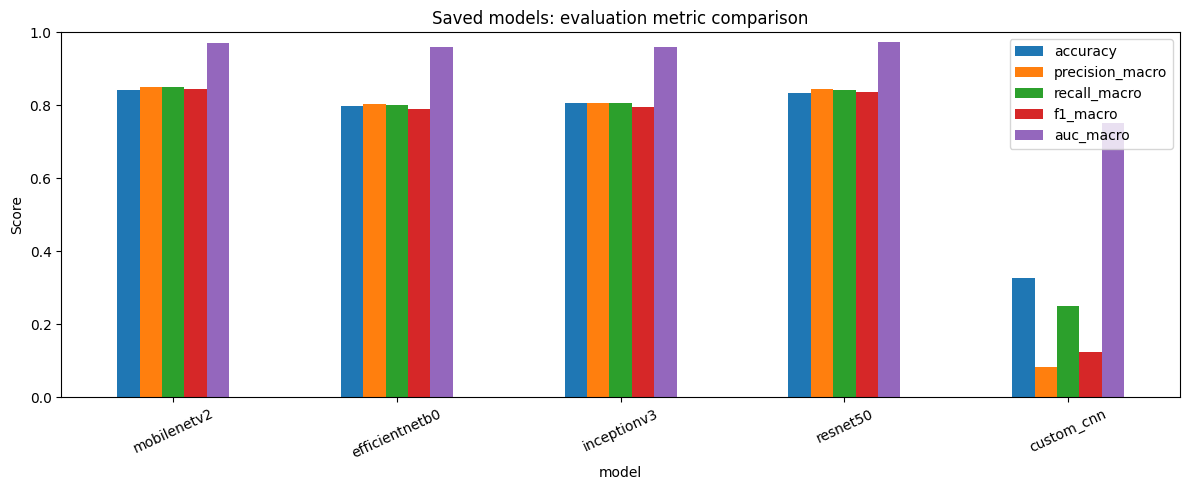

In [ ]:
metric_columns = ["accuracy", "precision_macro", "recall_macro", "f1_macro", "auc_macro"]
metric_columns = [c for c in metric_columns if c in comparison.columns]
comparison.set_index("model")[metric_columns].plot(kind="bar", figsize=(12, 5))
plt.title("Saved models: evaluation metric comparison")
plt.ylabel("Score"); plt.ylim(0, 1); plt.xticks(rotation=25)
plt.tight_layout(); plt.show()

### Hyperparameter tuning and cross-validation

The saved comparison was not produced using GridSearchCV or RandomizedSearchCV. Deep CNNs are computationally expensive to cross-validate, and the current runs used a fixed short configuration: five frozen-backbone epochs for transfer models and two smoke-test epochs for the custom CNN. Callbacks in the training script include EarlyStopping, ReduceLROnPlateau, and ModelCheckpoint. A future controlled study could tune learning rate, dropout, batch size, and fine-tuning depth using validation data, then evaluate once on the held-out test set.

### Optional training cell — disabled by default

In [ ]:
# WARNING: Training all five models can take a long time, especially on CPU.
# Leave RUN_TRAINING=False for submission review. Enable only when you intentionally want to retrain.
RUN_TRAINING = False

if RUN_TRAINING:
    from src.train import fit
    for model_name in ["custom_cnn", "mobilenetv2", "efficientnetb0", "resnet50", "inceptionv3"]:
        epochs = 5
        ft_epochs = 0
        fit(model_name, epochs=epochs, ft_epochs=ft_epochs)
    print("Training completed. Re-run evaluation/report generation before updating README metrics.")
else:
    print("Training skipped; existing saved model results are being reviewed.")

Training skipped; existing saved model results are being reviewed.


### Evaluation metrics and business meaning

- **Accuracy:** Overall fraction of correct predictions. Easy to interpret, but can hide class-specific errors.
- **Macro precision:** Equal-weighted precision across classes; helps expose false-positive behavior across minority classes.
- **Macro recall:** Equal-weighted recall; helps reveal classes the model frequently misses.
- **Macro F1:** Harmonic mean of precision and recall per class, averaged equally across classes.
- **Macro ROC-AUC:** Measures ranking ability across thresholds in a one-vs-rest setting.
- **Confusion matrix:** Shows which classes are being confused.
- **Latency and model size:** Help estimate deployment constraints; measurements depend on hardware and environment.

For a medical-imaging context, per-class false negatives and false positives need review by qualified clinicians. No single metric demonstrates clinical reliability.

### Select a practical candidate

In [ ]:
if not comparison.empty:
    ranked = comparison.sort_values("f1_macro", ascending=False)
    display(ranked[["model", "accuracy", "f1_macro", "auc_macro", "size_mb", "latency_ms"]])
    print("Highest recorded macro-F1 model:", ranked.iloc[0]["model"])
    print("Deployment discussion: compare macro F1, class-specific errors, size, latency, and external validation.")

,model,accuracy,f1_macro,auc_macro,size_mb,latency_ms
0,mobilenetv2,0.841463,0.843269,0.971405,13.578080,29.392641
3,resnet50,0.833333,0.835785,0.974125,101.330912,173.949041
2,inceptionv3,0.804878,0.796593,0.960629,94.590904,83.748317
1,efficientnetb0,0.796748,0.790220,0.959911,20.938672,87.164720
4,custom_cnn,0.325203,0.122699,0.751899,15.004200,40.786627


Highest recorded macro-F1 model: mobilenetv2
Deployment discussion: compare macro F1, class-specific errors, size, latency, and external validation.


**Current recommendation:** MobileNetV2 is the most practical candidate among the saved runs because it has the highest recorded accuracy and macro F1 while remaining small and fast. ResNet50 has a slightly higher macro ROC-AUC but substantially greater size and latency. This is a prototype-level engineering choice, not a medical-device recommendation.

## 8. Explainability with Grad-CAM

Grad-CAM creates a coarse heatmap indicating image regions that contribute to a selected CNN prediction. The Streamlit application includes this visualization. A heatmap can help inspect model behavior, but it does not establish that the model attends to clinically valid anatomy or that the prediction is correct.

In [ ]:
# Optional smoke test of the project's Grad-CAM implementation.
# Requires a dataset image and a downloaded saved model. This cell does not train.
RUN_GRADCAM = False
if RUN_GRADCAM and DATA_DIR.exists():
    from src.gradcam import gradcam
    sample_path = next((p for p in (DATA_DIR / "test").rglob("*") if p.is_file() and p.suffix.lower() in {".jpg",".jpeg",".png",".bmp",".webp"}), None)
    model_path = REPO_DIR / "models" / "mobilenetv2.h5"
    if sample_path and model_path.exists():
        model = keras.models.load_model(model_path, compile=False)
        with Image.open(sample_path) as im:
            image = np.asarray(im.convert("RGB").resize(IMG_SIZE), dtype=np.float32) / 255.0
        print("Sample image:", sample_path.name, "model:", model_path.name)
        print("The application calls the project Grad-CAM helper for the selected model.")
        print("If this helper's signature differs in your repository version, use the working Diagnose page in Streamlit.")
    else:
        print("Need a test image and models/mobilenetv2.h5 to run this optional cell.")
else:
    print("Grad-CAM demo skipped by default; verify it interactively in the Streamlit Diagnose tab.")

Grad-CAM demo skipped by default; verify it interactively in the Streamlit Diagnose tab.


In [ ]:
import tensorflow as tf, keras
print("TensorFlow:", tf.__version__)
print("Keras:", keras.__version__)

TensorFlow: 2.21.0
Keras: 3.13.2


In [ ]:
from pathlib import Path
import h5py

p = Path("/content/NeuroScan-AI-Brain-Tumor-Classification/models/mobilenetv2.h5")

print("Model exists:", p.is_file())
if p.is_file():
    print("Model size (MB):", round(p.stat().st_size / (1024 * 1024), 2))
    with h5py.File(p, "r") as f:
        print("HDF5 file opens:", True)
        print("Contains model configuration:", "model_config" in f.attrs)
        print("Contains weights:", "model_weights" in f)

Model exists: True
Model size (MB): 12.95
HDF5 file opens: True
Contains model configuration: True
Contains weights: True


In [44]:

import tensorflow as tf
import h5py
import json
import tempfile
import shutil
from pathlib import Path

model_path = Path(
    "/content/NeuroScan-AI-Brain-Tumor-Classification/models/mobilenetv2.h5"
)

# Copy the original model so it remains unchanged.
compatible_path = Path(tempfile.gettempdir()) / "mobilenetv2_compat.h5"
shutil.copy2(model_path, compatible_path)

# Remove obsolete Keras configuration fields from the copied model.
with h5py.File(compatible_path, "r+") as f:
    config = json.loads(f.attrs["model_config"])

    def clean_config(obj):
        if isinstance(obj, dict):
            if obj.get("class_name") == "BatchNormalization":
                layer_config = obj.get("config", {})
                for key in (
                    "renorm",
                    "renorm_clipping",
                    "renorm_momentum",
                    "input_axes",
                    "output_axes",
                ):
                    layer_config.pop(key, None)

            for value in obj.values():
                clean_config(value)

        elif isinstance(obj, list):
            for value in obj:
                clean_config(value)

    clean_config(config)
    f.attrs.modify("model_config", json.dumps(config))

model = tf.keras.models.load_model(
    str(compatible_path),
    compile=False
)

print("Model loaded successfully:", model.name)
print("Input shape:", model.input_shape)
print("Output shape:", model.output_shape)


Model loaded successfully: mobilenetv2
Input shape: (None, 224, 224, 3)
Output shape: (None, 4)


In [45]:
import numpy as np
from pathlib import Path
from PIL import Image

test_dir = Path("/content/NeuroScan-AI-Brain-Tumor-Classification/data/Tumour/test")
classes = ["glioma", "meningioma", "no_tumor", "pituitary"]

images = [
    p for p in test_dir.rglob("*")
    if p.suffix.lower() in (".jpg", ".jpeg", ".png", ".bmp")
]

if not images:
    raise FileNotFoundError(f"No test images found under {test_dir}")

image_path = images[0]
image = Image.open(image_path).convert("RGB").resize((224, 224))
x = np.asarray(image, dtype=np.float32)[None, ...] / 255.0

predictions = model.predict(x, verbose=0)[0]
predicted_index = int(np.argmax(predictions))

print("Image:", image_path)
print("Actual class:", image_path.parent.name)
print("Predicted class:", classes[predicted_index])
print(f"Confidence: {predictions[predicted_index] * 100:.2f}%")
print("Probabilities:", dict(zip(classes, predictions.tolist())))

Image: /content/NeuroScan-AI-Brain-Tumor-Classification/data/Tumour/test/pituitary/Tr-pi_0347_jpg.rf.4235c24459b415bc6c1839b1b7d00c02.jpg
Actual class: pituitary
Predicted class: pituitary
Confidence: 98.97%
Probabilities: {'glioma': 0.00025648498558439314, 'meningioma': 0.009357182309031487, 'no_tumor': 0.0006494130357168615, 'pituitary': 0.9897368550300598}


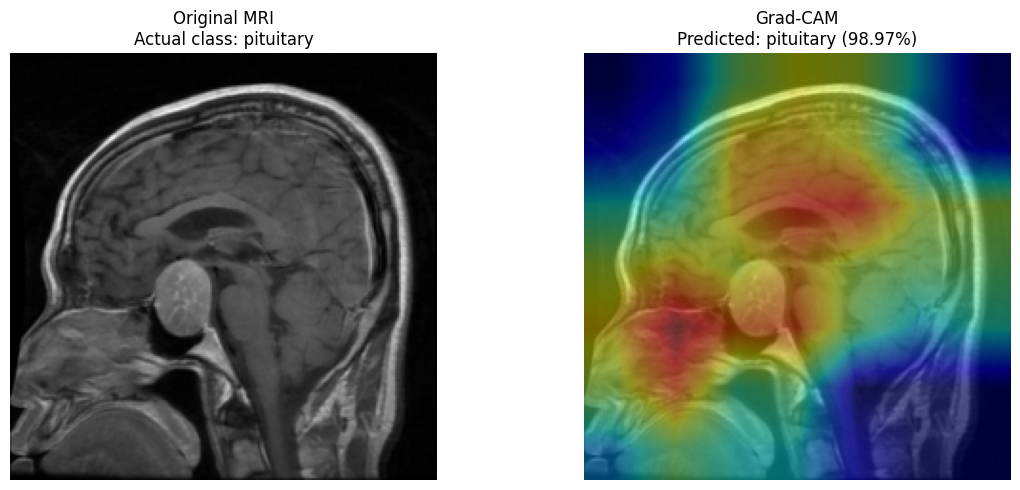

Image: /content/NeuroScan-AI-Brain-Tumor-Classification/data/Tumour/test/pituitary/Tr-pi_0347_jpg.rf.4235c24459b415bc6c1839b1b7d00c02.jpg
Predicted class: pituitary
Confidence: 98.97%


In [50]:
import numpy as np
import tensorflow as tf
import matplotlib.pyplot as plt
from pathlib import Path
from PIL import Image

# Use the already-loaded MobileNetV2 model
model = model

# Find a test MRI image
test_dir = Path("/content/NeuroScan-AI-Brain-Tumor-Classification/data/Tumour/test")
classes = ["glioma", "meningioma", "no_tumor", "pituitary"]

images = [
    p for p in test_dir.rglob("*")
    if p.suffix.lower() in [".jpg", ".jpeg", ".png", ".bmp"]
]

if not images:
    raise FileNotFoundError(
        "No test images found. Check the dataset folder in the Colab Files panel."
    )

# Select an image
image_path = images[0]
original = Image.open(image_path).convert("RGB").resize((224, 224))
image_array = np.asarray(original, dtype=np.float32) / 255.0
input_tensor = tf.convert_to_tensor(image_array[None, ...])

# Locate the final convolutional layer
conv_layer = model.get_layer("Conv_1")

# Build a Grad-CAM model using the model's own input tensor
grad_model = tf.keras.Model(
    inputs=model.inputs,
    outputs=[conv_layer.output, model.output]
)

# Calculate gradients for the predicted class
with tf.GradientTape() as tape:
    conv_outputs, predictions = grad_model(input_tensor, training=False)
    class_index = tf.argmax(predictions[0])
    class_score = predictions[:, class_index]

gradients = tape.gradient(class_score, conv_outputs)

if gradients is None:
    raise RuntimeError(
        "Gradients could not be calculated. Check the selected convolutional layer."
    )

# Generate heatmap
weights = tf.reduce_mean(gradients, axis=(1, 2))
heatmap = tf.reduce_sum(
    conv_outputs[0] * weights[0][None, None, :],
    axis=-1
)
heatmap = tf.maximum(heatmap, 0)
heatmap = heatmap / (tf.reduce_max(heatmap) + 1e-8)
heatmap = tf.image.resize(
    heatmap[..., None], (224, 224)
).numpy().squeeze()

# Display results
predicted_index = int(tf.argmax(predictions[0]))
confidence = float(predictions[0][predicted_index]) * 100

plt.figure(figsize=(12, 5))

plt.subplot(1, 2, 1)
plt.imshow(original)
plt.title(f"Original MRI\nActual class: {image_path.parent.name}")
plt.axis("off")

plt.subplot(1, 2, 2)
plt.imshow(original)
plt.imshow(heatmap, cmap="jet", alpha=0.45, vmin=0, vmax=1)
plt.title(
    f"Grad-CAM\nPredicted: {classes[predicted_index]} ({confidence:.2f}%)"
)
plt.axis("off")

plt.tight_layout()
plt.show()

print("Image:", image_path)
print("Predicted class:", classes[predicted_index])
print(f"Confidence: {confidence:.2f}%")

## 9. Deployment and reproducibility

The Streamlit application is launched locally with `streamlit run app/app.py`. It supports image upload, model selection, predicted class probabilities, and Grad-CAM visualization. The application is labeled for research/education and not for clinical decisions.

Repository: https://github.com/Kusuma-Ramesh/NeuroScan-AI-Brain-Tumor-Classification

In [ ]:
# Check that the core project artifacts are present.
expected_paths = [
    "app/app.py", "src/config.py", "src/data.py", "src/models.py",
    "src/train.py", "src/evaluate.py", "src/gradcam.py",
    "reports/comparison.csv", "README.md"
]
artifact_check = pd.DataFrame({
    "path": expected_paths,
    "exists": [(REPO_DIR / item).exists() for item in expected_paths]
})
display(artifact_check)

,path,exists
0,app/app.py,True
1,src/config.py,True
2,src/data.py,True
3,src/models.py,True
4,src/train.py,True
5,src/evaluate.py,True
6,src/gradcam.py,True
7,reports/comparison.csv,True
8,README.md,True


## 10. Limitations and future work

1. Train the custom CNN for a planned, monitored duration and tune it fairly; the current two-epoch result is only a smoke-test baseline.
2. Consider fine-tuning the upper layers of the best transfer model using validation-based early stopping.
3. Check exact and near-duplicate images across train, validation, and test splits to reduce leakage risk.
4. Evaluate per-class sensitivity/specificity and calibration; retain a truly untouched test set.
5. Validate on independent datasets from different institutions and scanners.
6. Review data provenance, labeling quality, demographics, and potential dataset bias.
7. Have qualified medical professionals review the model and any explanations before any research translation.
8. Do not use the current model for diagnosis, treatment, or patient triage.

## Conclusion

This project implements a complete educational pipeline for four-class brain MRI image classification: dataset inspection, preprocessing, augmentation, a custom CNN, four transfer-learning models, evaluation reports, model comparison, Grad-CAM, and a Streamlit interface. In the recorded short runs, MobileNetV2 provided the best balance of accuracy, macro F1, model size, and measured latency. The custom CNN is undertrained, fine-tuning has not been performed, and duplicate-image checks and external validation remain important limitations. The work is a research/education prototype only and is not clinically validated.